# Visualización · Gráficas científicas

Gráficas habituales en ciencia con `matplotlib` y `numpy` sobre datos meteorológicos **sintéticos** de estaciones canarias, generados con semilla fija: bandas de mínimo y máximo, ajustes polinómicos, barras de error asimétricas, funciones de dos variables (`contour`, `imshow`, `pcolormesh`, superficies 3D), campos de viento con `quiver`, regresión con atípicos, ejes gemelos, escala logarítmica y composiciones con `subplot_mosaic`. Las comprobaciones se hacen sobre los valores calculados, no sobre los dibujos. Ideas de [Project Pythia · AtmosCol 2023](https://github.com/ProjectPythia/AtmosCol-2023) y del [curso de Python científico de hmedrano](https://github.com/hmedrano/curso-python-cientifico).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (7, 3), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. Series sintéticas de varias estaciones

Generar diez años (2015-2024) de temperatura diaria media, mínima y máxima para cinco estaciones con un ciclo anual (coseno con el mínimo a mediados de febrero), una ligera tendencia de calentamiento y un ruido autocorrelacionado (cada día se parece al anterior), y la precipitación diaria de La Laguna, más probable en invierno. Guardarlo en un `DataFrame` largo y dibujar la temperatura media de 2024 de todas las estaciones.

(18265, 6)
            mean   min   max
estacion                    
Arrecife    21.1  14.8  27.6
Izaña       10.7  -0.1  21.2
La Laguna   17.2   9.9  24.8
Santa Cruz  21.9  15.8  28.2
Valverde    16.6   9.1  23.5


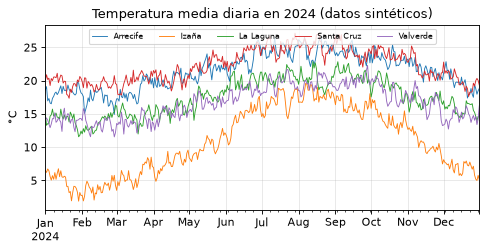

In [2]:
rng = np.random.default_rng(2024)
fechas = pd.date_range("2015-01-01", "2024-12-31", freq="D")
dia = fechas.day_of_year.to_numpy()
años = (fechas.year - 2015 + dia / 365.25).to_numpy()

# altitud (m), media anual (°C), amplitud del ciclo (°C), oscilación diaria (°C)
estaciones = {
    "Santa Cruz": (35, 21.8, 3.0, 6.0),
    "Arrecife": (15, 21.0, 3.4, 7.0),
    "La Laguna": (600, 17.0, 3.8, 8.0),
    "Valverde": (600, 16.5, 3.2, 7.0),
    "Izaña": (2370, 10.5, 7.0, 9.0),
}
TENDENCIA = 0.03  # °C por año


def ruido_ar1(n, phi=0.7, sigma=0.8):
    e = rng.normal(0, sigma, n)
    for i in range(1, n):
        e[i] += phi * e[i - 1]
    return e


tablas = []
for nombre, (altitud, media, amplitud, oscilacion) in estaciones.items():
    tmed = media - amplitud * np.cos(2 * np.pi * (dia - 45) / 365.25) + TENDENCIA * años + ruido_ar1(len(fechas))
    mitad = oscilacion / 2 + rng.gamma(4, 0.25, len(fechas))
    tablas.append(pd.DataFrame({"fecha": fechas, "estacion": nombre, "altitud": altitud,
                                "tmed": tmed, "tmin": tmed - mitad, "tmax": tmed + mitad}))
datos = pd.concat(tablas, ignore_index=True)

prob_lluvia = 0.04 + 0.30 * np.clip(np.cos(2 * np.pi * (dia - 15) / 365.25), 0, None)
lluvia = np.where(rng.random(len(fechas)) < prob_lluvia, rng.gamma(0.7, 9, len(fechas)), 0.0)
precipitacion = pd.Series(lluvia, index=fechas, name="La Laguna")

print(datos.shape)
print(datos.groupby("estacion")["tmed"].agg(["mean", "min", "max"]).round(1))

ancha = datos.pivot(index="fecha", columns="estacion", values="tmed")
fig, ax = plt.subplots()
ancha.loc["2024"].plot(ax=ax, lw=0.8)
ax.set(title="Temperatura media diaria en 2024 (datos sintéticos)", xlabel="", ylabel="°C")
ax.legend(ncol=5, fontsize=7, loc="upper center")
plt.show()

assert (datos["tmin"] <= datos["tmed"]).all() and (datos["tmed"] <= datos["tmax"]).all()
for nombre, (_, media, *_) in estaciones.items():
    assert abs(ancha[nombre].mean() - (media + TENDENCIA * 5)) < 0.5

## 2. Banda de mínimo y máximo por día del año

Para La Laguna, calcular para cada día del año (1 a 365) el mínimo, el máximo y la media de la temperatura media de los diez años. Dibujar la banda entre mínimo y máximo con `fill_between`, la media encima y la serie de 2024 aparte. Comprobar que la media queda dentro de la banda y que el día más cálido de la climatología cae en agosto o septiembre.

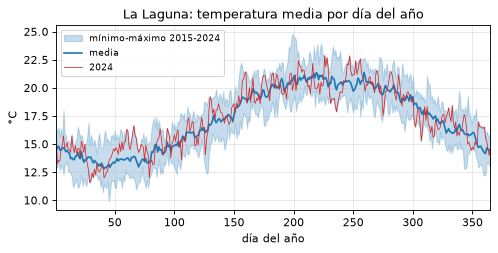

Día más cálido de la climatología: 259 (16/09)


In [3]:
laguna = ancha["La Laguna"]
laguna = laguna[laguna.index.day_of_year <= 365]
clima = laguna.groupby(laguna.index.day_of_year).agg(["min", "mean", "max"])
d2024 = laguna.loc["2024"]

fig, ax = plt.subplots()
ax.fill_between(clima.index, clima["min"], clima["max"], color="tab:blue", alpha=0.25, label="mínimo-máximo 2015-2024")
ax.plot(clima.index, clima["mean"], color="tab:blue", lw=1.5, label="media")
ax.plot(d2024.index.day_of_year, d2024, color="tab:red", lw=0.7, label="2024")
ax.set(title="La Laguna: temperatura media por día del año", xlabel="día del año", ylabel="°C", xlim=(1, 365))
ax.legend(fontsize=8)
plt.show()

mas_calido = int(clima["mean"].idxmax())
print("Día más cálido de la climatología:", mas_calido, (pd.Timestamp(2023, 1, 1) + pd.Timedelta(days=mas_calido - 1)).strftime("(%d/%m)"))
assert (clima["min"] <= clima["mean"]).all() and (clima["mean"] <= clima["max"]).all()
assert 213 <= mas_calido <= 273

## 3. Ajuste polinómico: infra y sobreajuste

Con las 12 medias mensuales de 2015 de Santa Cruz, situadas a mitad de cada mes, ajustar polinomios de grado 1, 2, 4 y 11 con `np.polynomial.Polynomial.fit` y dibujarlos sobre los datos. Medir el error (RMSE) frente a esos 12 puntos y frente a la climatología diaria de los otros nueve años: el error de entrenamiento baja siempre con el grado, pero el de prueba sube con el de grado 11, que pasa por todos los puntos y oscila entre ellos y en los extremos. Comprobar también que `np.polyfit` con `np.poly1d` da el mismo polinomio de grado 2 (sus coeficientes van del mayor grado al menor; los de `Polynomial` se recuperan con `convert()`).

grado  RMSE entrenamiento  RMSE prueba
    1               2.043        1.961
    2               1.279        1.146
    4               0.424        0.618
   11               0.000       34.487


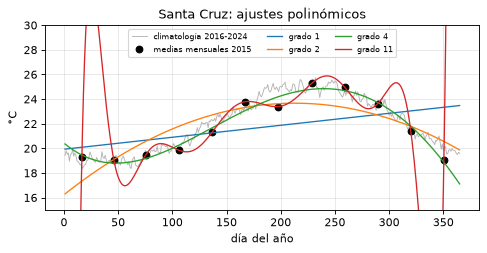


Grado 2 con polyfit (del mayor grado al menor): -0.0001639, 0.06977, 16.24 · p(200) = 23.641 °C


In [4]:
santa_cruz = ancha["Santa Cruz"]
mensual = santa_cruz.loc["2015"].resample("MS").mean()
x = (mensual.index.day_of_year + mensual.index.days_in_month / 2).to_numpy()
y = mensual.to_numpy()

resto = santa_cruz.loc["2016":]
resto = resto[resto.index.day_of_year <= 365]
clima_sc = resto.groupby(resto.index.day_of_year).mean()


def rmse(p, xs, ys):
    return float(np.sqrt(np.mean((p(xs) - ys) ** 2)))


grados = [1, 2, 4, 11]
ajustes = {g: np.polynomial.Polynomial.fit(x, y, g) for g in grados}
dias = np.arange(1, 366)

fig, ax = plt.subplots()
ax.plot(clima_sc.index, clima_sc, color="0.7", lw=0.8, label="climatología 2016-2024")
ax.plot(x, y, "ko", label="medias mensuales 2015")
print(f"{'grado':>5} {'RMSE entrenamiento':>19} {'RMSE prueba':>12}")
errores = {}
for g, p in ajustes.items():
    errores[g] = rmse(p, x, y), rmse(p, clima_sc.index.to_numpy(), clima_sc.to_numpy())
    print(f"{g:>5} {errores[g][0]:>19.3f} {errores[g][1]:>12.3f}")
    ax.plot(dias, p(dias), lw=1.2, label=f"grado {g}")
ax.set(ylim=(15, 30), xlabel="día del año", ylabel="°C", title="Santa Cruz: ajustes polinómicos")
ax.legend(fontsize=7, ncol=3)
plt.show()

entrenamiento = [errores[g][0] for g in grados]
assert entrenamiento == sorted(entrenamiento, reverse=True) and errores[11][0] < 1e-6
assert errores[11][1] > errores[4][1] and errores[1][1] > errores[2][1]

coeficientes = np.polyfit(x, y, 2)
p2 = np.poly1d(coeficientes)
print(f"\nGrado 2 con polyfit (del mayor grado al menor): {", ".join(f"{c:.4g}" for c in p2.coeffs)} · p(200) = {p2(200):.3f} °C")
assert np.allclose(coeficientes[::-1], ajustes[2].convert().coef)
assert np.allclose(p2(dias), ajustes[2](dias))

## 4. Media por estación con barras de error asimétricas

Calcular la temperatura media de cada estación y dibujarla con `errorbar`, con barras que vayan del mínimo al máximo diario. Como la media no está en el centro del intervalo, el error es asimétrico: `yerr` recibe dos filas, la distancia hacia abajo (media − mínimo) y hacia arriba (máximo − media). Ordenar las estaciones por altitud y girar las etiquetas del eje.

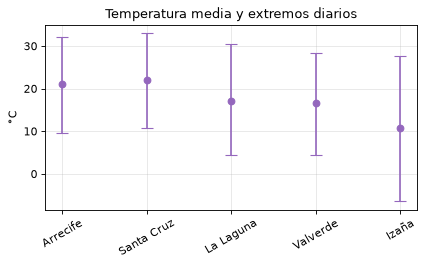

            altitud  media  minimo  maximo
estacion                                  
Arrecife         15   21.1     9.7    32.1
Santa Cruz       35   21.9    10.8    33.0
La Laguna       600   17.2     4.4    30.4
Valverde        600   16.6     4.4    28.3
Izaña          2370   10.7    -6.4    27.5


In [5]:
resumen = (datos.groupby("estacion")
           .agg(altitud=("altitud", "first"), media=("tmed", "mean"), minimo=("tmin", "min"), maximo=("tmax", "max"))
           .sort_values("altitud"))
yerr = np.vstack([resumen["media"] - resumen["minimo"], resumen["maximo"] - resumen["media"]])

fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(resumen.index, resumen["media"], yerr=yerr, fmt="o", capsize=5, color="tab:purple")
ax.set(ylabel="°C", title="Temperatura media y extremos diarios")
ax.tick_params(axis="x", labelrotation=30)
plt.show()

print(resumen.round(1))
assert (yerr >= 0).all()
assert np.allclose(resumen["media"] - yerr[0], resumen["minimo"]) and np.allclose(resumen["media"] + yerr[1], resumen["maximo"])
assert resumen["media"].idxmin() == "Izaña"

## 5. Funciones de dos variables: `meshgrid`, `fromfunction` y curvas de nivel

Modelar una isla como una montaña gaussiana de 3700 m centrada en $(5, -3)$ km, $h(x, y) = 3700\, e^{-\frac{(x-5)^2 + (y+3)^2}{2 \cdot 12^2}}$, en una rejilla de $[-40, 40] \times [-30, 30]$ km con paso de 1 km, y la temperatura a partir del gradiente atmosférico estándar, $T = 22 - 0.0065\,h$. Evaluar $h$ con `np.meshgrid` y con `np.fromfunction` (que pasa los índices de cada celda) y comprobar que coinciden. Dibujar $T$ con `contourf` y las curvas de nivel de $h$ con `contour` y sus etiquetas con `clabel`.

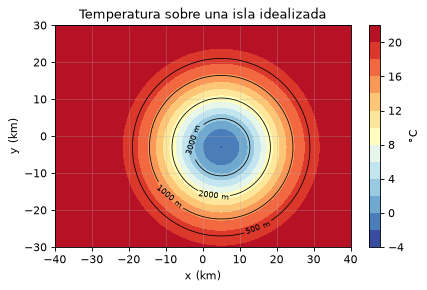

Forma de la rejilla: (61, 81) · T mínima: -2.05 °C


In [6]:
X0, Y0, ALTURA, SIGMA = 5, -3, 3700, 12
xs = np.arange(-40, 41)
ys = np.arange(-30, 31)


def altura(x, y):
    return ALTURA * np.exp(-((x - X0) ** 2 + (y - Y0) ** 2) / (2 * SIGMA**2))


X, Y = np.meshgrid(xs, ys)
H = altura(X, Y)
H_indices = np.fromfunction(lambda i, j: altura(xs[0] + j, ys[0] + i), (len(ys), len(xs)))
T = 22 - 0.0065 * H

fig, ax = plt.subplots(figsize=(6, 3.6))
relleno = ax.contourf(X, Y, T, levels=12, cmap="RdYlBu_r")
curvas = ax.contour(X, Y, H, levels=[500, 1000, 2000, 3000], colors="k", linewidths=0.7)
ax.clabel(curvas, fmt="%d m", fontsize=7)
fig.colorbar(relleno, ax=ax, label="°C")
ax.set(aspect="equal", xlabel="x (km)", ylabel="y (km)", title="Temperatura sobre una isla idealizada")
plt.show()

print("Forma de la rejilla:", H.shape, "· T mínima:", round(T.min(), 2), "°C")
assert H.shape == (len(ys), len(xs)) and np.allclose(H, H_indices)
assert np.isclose(T.min(), 22 - 0.0065 * ALTURA)

## 6. `imshow` con `extent` frente a `pcolormesh`

Dibujar la altura de la isla con `imshow` y con `pcolormesh`, cada una con su barra de color. `imshow` trata el array como una imagen: hay que darle `extent` con los límites en km y `origin="lower"` para que la fila 0 quede abajo; `pcolormesh` recibe directamente las coordenadas. Comprobar que la celda más alta del array (con `np.unravel_index`) corresponde a la cima en $(5, -3)$.

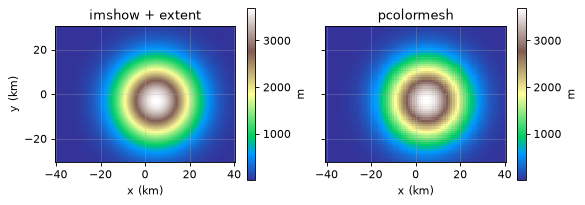

Cima en la fila 27, columna 45 → (x, y) = (5, -3) km


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
mitad = 0.5  # extent marca los bordes de las celdas, no sus centros
im = ax1.imshow(H, extent=[xs[0] - mitad, xs[-1] + mitad, ys[0] - mitad, ys[-1] + mitad], origin="lower", cmap="terrain")
fig.colorbar(im, ax=ax1, label="m")
ax1.set(title="imshow + extent", xlabel="x (km)", ylabel="y (km)", aspect="equal")
malla = ax2.pcolormesh(X, Y, H, shading="nearest", cmap="terrain")
fig.colorbar(malla, ax=ax2, label="m")
ax2.set(title="pcolormesh", xlabel="x (km)", aspect="equal")
plt.show()

fila, columna = np.unravel_index(H.argmax(), H.shape)
print(f"Cima en la fila {fila}, columna {columna} → (x, y) = ({xs[columna]}, {ys[fila]}) km")
assert (xs[columna], ys[fila]) == (X0, Y0) and (X[fila, columna], Y[fila, columna]) == (X0, Y0)

## 7. Superficie 3D

Dibujar la montaña como superficie con `plot_surface` en unos ejes `projection="3d"`, coloreada por altura, y calcular el volumen de la montaña sumando $h$ por el área de cada celda (1 km²). Compararlo con la integral exacta de la gaussiana sobre el rectángulo, que se separa en dos factores con la función de error, $\int_a^b e^{-\frac{(x-x_0)^2}{2\sigma^2}}dx = \sigma\sqrt{\frac{\pi}{2}}\left[\operatorname{erf}\frac{b-x_0}{\sigma\sqrt2} - \operatorname{erf}\frac{a-x_0}{\sigma\sqrt2}\right]$, y con el volumen de la gaussiana completa, $2\pi\sigma^2 \cdot 3700$ m, del que una parte queda fuera de la rejilla.

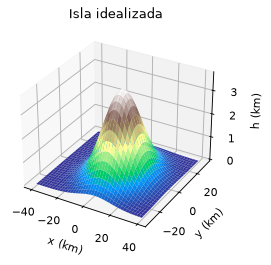

Volumen en la rejilla: 3297.0 km³ · exacto en el rectángulo: 3296.9 km³ · gaussiana completa: 3347.7 km³


In [8]:
fig = plt.figure(figsize=(5, 3.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, H / 1000, cmap="terrain", linewidth=0, rstride=2, cstride=2)
ax.set(xlabel="x (km)", ylabel="y (km)", zlabel="h (km)", title="Isla idealizada")
ax.view_init(elev=30, azim=-60)
plt.show()

from math import erf, pi, sqrt


def integral_1d(a, b, centro):
    k = SIGMA * sqrt(2)
    return SIGMA * sqrt(pi / 2) * (erf((b - centro) / k) - erf((a - centro) / k))


volumen = H.sum()  # km² · m: cada celda mide 1 km²
# Las celdas van de x - 0,5 a x + 0,5
rectangulo = ALTURA * integral_1d(xs[0] - 0.5, xs[-1] + 0.5, X0) * integral_1d(ys[0] - 0.5, ys[-1] + 0.5, Y0)
completa = 2 * pi * SIGMA**2 * ALTURA
print(f"Volumen en la rejilla: {volumen / 1000:.1f} km³ · exacto en el rectángulo: {rectangulo / 1000:.1f} km³"
      f" · gaussiana completa: {completa / 1000:.1f} km³")
assert abs(volumen / rectangulo - 1) < 1e-3 and volumen < completa

## 8. Campo de viento con `quiver`

Modelar el alisio del nordeste (sopla **desde** 45°, a 8 m/s) que se frena sobre la montaña en proporción a su altura (hasta un 70 % en la cima). Calcular las componentes $u$ (hacia el este) y $v$ (hacia el norte), dibujar las flechas con `quiver` sobre las curvas de nivel (una de cada cuatro para no saturar) y calcular la velocidad y la dirección meteorológica $\arctan2(-u, -v)$ en grados. Comprobar que lejos de la isla el viento viene del NE a 8 m/s y que en la cima se reduce al 30 %.

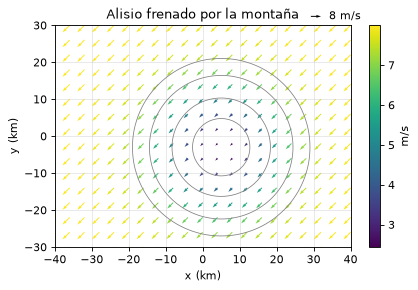

Esquina NE: 8.00 m/s desde 45° · cima: 2.40 m/s


In [9]:
VELOCIDAD, DIRECCION = 8.0, 45.0
freno = 1 - 0.7 * H / ALTURA
U = -VELOCIDAD * np.sin(np.radians(DIRECCION)) * freno
V = -VELOCIDAD * np.cos(np.radians(DIRECCION)) * freno
velocidad = np.hypot(U, V)
direccion = np.degrees(np.arctan2(-U, -V)) % 360

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.contour(X, Y, H, levels=[500, 1000, 2000, 3000], colors="0.5", linewidths=0.7)
paso = slice(None, None, 4)
flechas = ax.quiver(X[paso, paso], Y[paso, paso], U[paso, paso], V[paso, paso], velocidad[paso, paso], cmap="viridis")
ax.quiverkey(flechas, 0.9, 1.04, 8, "8 m/s", labelpos="E")
fig.colorbar(flechas, ax=ax, label="m/s")
ax.set(aspect="equal", xlabel="x (km)", ylabel="y (km)", title="Alisio frenado por la montaña")
plt.show()

print(f"Esquina NE: {velocidad[-1, -1]:.2f} m/s desde {direccion[-1, -1]:.0f}° · cima: {velocidad.min():.2f} m/s")
assert np.allclose(direccion, DIRECCION)
assert np.isclose(velocidad[-1, -1], VELOCIDAD, atol=0.01) and np.isclose(velocidad.min(), 0.3 * VELOCIDAD)

## 9. Altitud y temperatura: regresión y atípicos

Generar 30 estaciones con altitudes entre 0 y 2400 m y una temperatura media anual que baja 0,65 °C cada 100 m, más ruido, e introducir tres atípicos: dos estaciones altas más cálidas por la inversión térmica del alisio y una hondonada fría cerca de la costa. Ajustar la recta con `np.polyfit` y estimar el gradiente en °C por 100 m; detectar los atípicos por sus residuos con la desviación absoluta mediana (más robusta que la típica), repetir el ajuste sin ellos y dibujarlo todo marcando y etiquetando los atípicos.

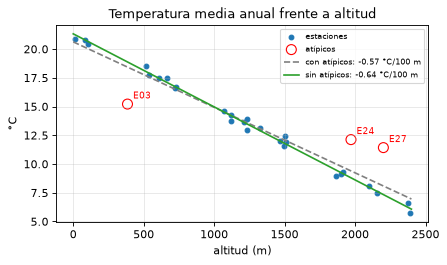

Atípicos detectados: ['E03', 'E24', 'E27']
Gradiente térmico: -0.570 °C/100 m con atípicos, -0.635 sin ellos


In [10]:
rng = np.random.default_rng(7)
n = 30
altitud = np.sort(rng.uniform(0, 2400, n)).round()
temperatura = 21.5 - 0.0065 * altitud + rng.normal(0, 0.35, n)
atipicos_reales = np.array([3, 24, 27])
temperatura[atipicos_reales] += [-3.5, 3.5, 4.0]

pendiente, ordenada = np.polyfit(altitud, temperatura, 1)
residuos = temperatura - (pendiente * altitud + ordenada)
mad = np.median(np.abs(residuos - np.median(residuos)))
z_robusta = 0.6745 * (residuos - np.median(residuos)) / mad
atipicos = np.flatnonzero(np.abs(z_robusta) > 3.5)
normales = np.setdiff1d(np.arange(n), atipicos)
pendiente2, ordenada2 = np.polyfit(altitud[normales], temperatura[normales], 1)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(altitud[normales], temperatura[normales], s=18, label="estaciones")
ax.scatter(altitud[atipicos], temperatura[atipicos], s=80, facecolors="none", edgecolors="red", label="atípicos")
for i in atipicos:
    ax.annotate(f"E{i:02d}", (altitud[i], temperatura[i]), xytext=(5, 5), textcoords="offset points", fontsize=8, color="red")
recta = np.array([0, 2400])
ax.plot(recta, pendiente * recta + ordenada, "--", color="0.5", label=f"con atípicos: {100 * pendiente:.2f} °C/100 m")
ax.plot(recta, pendiente2 * recta + ordenada2, color="tab:green", label=f"sin atípicos: {100 * pendiente2:.2f} °C/100 m")
ax.set(xlabel="altitud (m)", ylabel="°C", title="Temperatura media anual frente a altitud")
ax.legend(fontsize=7)
plt.show()

print("Atípicos detectados:", [f"E{i:02d}" for i in atipicos])
print(f"Gradiente térmico: {100 * pendiente:.3f} °C/100 m con atípicos, {100 * pendiente2:.3f} sin ellos")
cov = np.cov(altitud[normales], temperatura[normales])
assert np.isclose(pendiente2, cov[0, 1] / cov[0, 0])
assert set(atipicos) == set(atipicos_reales)
assert abs(100 * pendiente2 + 0.65) < abs(100 * pendiente + 0.65) and abs(100 * pendiente2 + 0.65) < 0.05

## 10. Ejes gemelos y escala logarítmica

Dibujar el climograma de La Laguna: la temperatura media de cada mes como línea en el eje izquierdo y la precipitación media mensual como barras en un eje gemelo a la derecha (`twinx`), cada uno con su escala y su color, subiendo el eje original con `set_zorder` para que las barras no tapen la línea. Al lado, el histograma de la lluvia de los días que llueve con el eje $y$ en escala logarítmica, donde se ve que los días de mucha lluvia son cientos de veces menos frecuentes que los de poca.

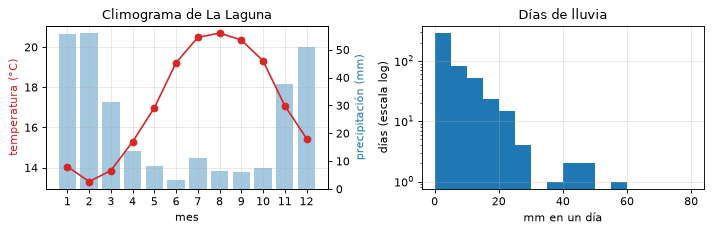

Mes más lluvioso: 2 · más seco: 6
Días con lluvia: 473 · primeros intervalos: [290  82  53  23]


In [11]:
meses = np.arange(1, 13)
temp_mes = ancha["La Laguna"].groupby(ancha.index.month).mean()
lluvia_mes = precipitacion.resample("MS").sum()
lluvia_mes = lluvia_mes.groupby(lluvia_mes.index.month).mean()

fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(9, 3))
ax1.plot(meses, temp_mes, "o-", color="tab:red")
ax1.set(xticks=meses, xlabel="mes", title="Climograma de La Laguna")
ax1.set_ylabel("temperatura (°C)", color="tab:red")
ax2 = ax1.twinx()
ax2.bar(meses, lluvia_mes, color="tab:blue", alpha=0.4)
ax2.set_ylabel("precipitación (mm)", color="tab:blue")
ax2.grid(False)
# El eje gemelo se dibuja encima: se sube el original y se hace transparente su fondo
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

dias_lluvia = precipitacion[precipitacion > 0]
cuentas, bordes, _ = ax3.hist(dias_lluvia, bins=np.arange(0, 85, 5), color="tab:blue")
ax3.set(yscale="log", xlabel="mm en un día", ylabel="días (escala log)", title="Días de lluvia")
fig.tight_layout()
plt.show()

print("Mes más lluvioso:", int(lluvia_mes.idxmax()), "· más seco:", int(lluvia_mes.idxmin()))
print("Días con lluvia:", len(dias_lluvia), "· primeros intervalos:", cuentas[:4].astype(int))
assert lluvia_mes.idxmax() in (11, 12, 1, 2) and lluvia_mes.idxmin() in (6, 7, 8)
assert np.isclose(lluvia_mes.sum() * 10, precipitacion.sum())
assert cuentas[0] / cuentas[cuentas > 0][-1] > 100

## 11. Panel con `subplot_mosaic`

Componer un panel con `plt.subplot_mosaic` describiendo la disposición con texto: la evolución de la temperatura media anual de cada estación arriba, a lo ancho; un diagrama de cajas por estación a la derecha, ocupando dos filas; y abajo el histograma de las anomalías diarias (diferencia con la media de cada estación y día del año) y la dispersión de mínimas frente a máximas de Izaña. Estimar con `np.polyfit` la tendencia de cada estación, que debe acercarse a los 0,03 °C por año con los que se generaron los datos.

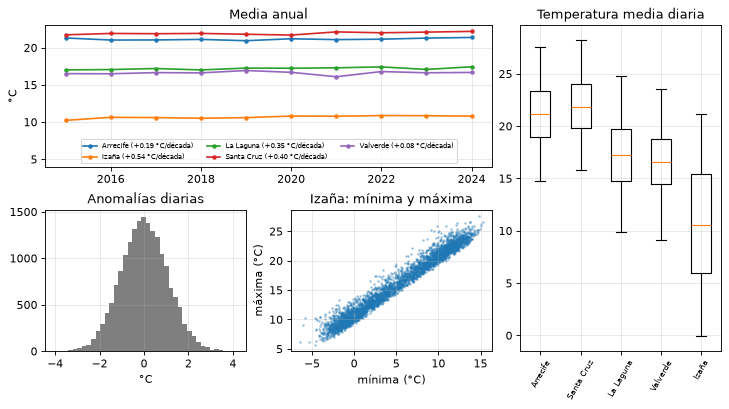

{'Arrecife': 0.019, 'Izaña': 0.054, 'La Laguna': 0.035, 'Santa Cruz': 0.04, 'Valverde': 0.008}


In [12]:
anual = ancha.groupby(ancha.index.year).mean()
tendencias = {e: np.polyfit(anual.index, anual[e], 1)[0] for e in anual.columns}
anomalias = ancha - ancha.groupby(ancha.index.day_of_year).transform("mean")
izana = datos[datos["estacion"] == "Izaña"]

fig, axs = plt.subplot_mosaic("""
    AAC
    BDC
    """, figsize=(9, 5), layout="constrained")
for e in anual.columns:
    axs["A"].plot(anual.index, anual[e], "o-", ms=3, label=f"{e} ({10 * tendencias[e]:+.2f} °C/década)")
axs["A"].set(title="Media anual", ylabel="°C", ylim=(4, 23))
axs["A"].legend(fontsize=6, ncol=3, loc="lower center")
axs["B"].hist(anomalias.to_numpy().ravel(), bins=40, color="tab:gray")
axs["B"].set(title="Anomalías diarias", xlabel="°C")
axs["C"].boxplot([ancha[e] for e in resumen.index], tick_labels=resumen.index)
axs["C"].tick_params(axis="x", labelrotation=60, labelsize=7)
axs["C"].set(title="Temperatura media diaria")
axs["D"].scatter(izana["tmin"], izana["tmax"], s=2, alpha=0.3)
axs["D"].set(title="Izaña: mínima y máxima", xlabel="mínima (°C)", ylabel="máxima (°C)")
plt.show()

print({e: round(float(t), 3) for e, t in tendencias.items()})
assert sorted(axs) == ["A", "B", "C", "D"]
assert all(abs(t - TENDENCIA) < 0.05 for t in tendencias.values())
assert abs(np.mean(list(tendencias.values())) - TENDENCIA) < 0.02
assert np.allclose(anomalias.groupby(anomalias.index.day_of_year).mean(), 0)